# 00 — Data creation: the life image

What one row of the simulated study **looks like**. The DGP emits a `C x T` array per
person; this notebook renders that array the way the study reads it, and nothing else —
there is no estimation here and no claim about any of it.

The image has three parts:

| part | what it carries |
|---|---|
| **x, twice** | the same bins read as **age** along the bottom and as **calendar year** along the top |
| **y** | the 12 social factors, ordered by **hierarchy**: upstream → midstream → downstream |
| **a separate section** | **disease and death**, on the same x-axis, never inside the image |

Death and disease sit apart deliberately. They are the outcome the pseudo-image is
supposed to predict, so putting them in the picture as a thirteenth channel would
draw the thing the study is trying to keep out of the input.

Read `doc/STATE.md` first; this notebook takes the DGP as it stands there
(N = 10,000, replicate 0, master seed 20260724) and adds no numbers to the ledger.

## Bootstrap

In [1]:
import sys
from pathlib import Path

# Anchor every path on the repo root regardless of where this is launched from.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "utils").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from utils import shared_paths as P

P.bootstrap()

%matplotlib inline

from datetime import date

import numpy as np

from utils.shared_dgp import MASTER_SEED, generate_dataset, load_config
from utils.shared_model_input import (
    OUTCOME_NAMES,
    build_model_input,
    model_input_path,
    write_model_input,
)
from utils.shared_style import load_style
from utils.data_creation_00_data_creation_life_image import (
    build_life_image,
    build_life_image_gallery,
    calendar_image,
    calendar_span,
    display_values,
    exemplars,
    image_limit,
    life_summary,
    save_calendar_image,
    save_figure,
)

STYLE = load_style("00_data_creation")
FIGURE_DIR = P.LIFE_IMAGE_FIGURE_DIR
SAVE_DATE = date.today().strftime("%Y%m%d")
FIGURE_DIR

PosixPath('/Users/valler/Python/life_pseudo_image/output/figures/data_creation/00_data_creation')

## The data

One scenario, at the sample size everything else in the project is reported at. The
figures below are pictures of *this* dataset, so the run is pinned the same way a
diagnostic run is: `(master_seed, scenario, N, replicate)` and nothing else.

`critical_period` is the scenario to look at first — its truth is a sharp window in
bins 5–8 (ages 58–66), so it is the one where a reader can ask "is the window visible
by eye?" and get an honest no. Any of the six can be swapped in below.

In [2]:
SCENARIO = "critical_period"
N = 10_000
REPLICATE = 0

cfg = load_config()
result = generate_dataset(
    SCENARIO, n=N, replicate=REPLICATE, config=cfg, master_seed=MASTER_SEED
)

meta = result.metadata
print(f"{SCENARIO}: seed={meta['seed']}  N={meta['N']:,}")
print(
    f"  disease {meta['realized_disease_incidence']:.4f}"
    f"   death {meta['realized_mortality']:.4f}"
    f"   attrition {meta['realized_attrition']:.4f}"
    f"   missing cells {meta['missing_fraction']:.4f}"
)
print("  (STATE.md ledger: disease 0.1427-0.1573, death 0.1964-0.2082, "
      "attrition 0.2969-0.3030, missing 0.4549-0.4565)")
print(f"  grid: C={cfg.C} channels x T={cfg.T} bins")

critical_period: seed=1544072896  N=10,000
  disease 0.1493   death 0.2040   attrition 0.2969   missing cells 0.4554
  (STATE.md ledger: disease 0.1427-0.1573, death 0.1964-0.2082, attrition 0.2969-0.3030, missing 0.4549-0.4565)
  grid: C=12 channels x T=20 bins


## What a cell shows

There are two ways to colour a cell, and neither is more correct than the other —
`display_values(result, mode)` returns either, and the colourbar always names which one
is on screen.

| mode | a cell reads as | good for |
|---|---|---|
| `peer` | **SD from peers of the same age** — the cell standardised across the population | comparing people; seeing all three streams at once |
| `raw` | **the observed value**, exactly as the DGP emitted it | knowing how big these numbers actually are |

`peer` is the default below because raw values are not on a common scale: each latent
stream is AR(1) with an individual intercept, so the stationary variance grows down the
hierarchy (population SD ≈ 2.7 / 3.4 / 7.3 for upstream / midstream / downstream) and one
colour limit renders upstream as near-flat beside a saturated downstream.

Both are display transforms. `result.X` is untouched and is what any model would be given.

The colour limit is computed once from the whole population and passed to every figure —
otherwise each person would be drawn on their own scale and the images could not be
compared.

In [3]:
values = display_values(result)
vlim = image_limit(values)

people = exemplars(result, cfg.T)
for label, person in people.items():
    print(f"{label:<28} person {person:>5}  —  {life_summary(result, person, cfg.T)}")

print(f"\ncolour limit: +/- {vlim:.2f} SD (99th percentile of |value|)")
print(f"cells never observed: {np.isnan(result.X).mean():.1%}")

Disease onset                person    20  —  born 1938, male — disease at age 76 (2014)
Death                        person    10  —  born 1932, male — death at age 64 (1996)
Left the panel               person     7  —  born 1935, male — event-free through age 90, last observed at age 86
Event-free, fully observed   person     0  —  born 1946, male — event-free through age 90

colour limit: +/- 2.59 SD (99th percentile of |value|)
cells never observed: 45.5%


## One life, in detail

The top section is the pseudo-image: 12 social factors down, 20 two-year bins across,
bracketed and named by stream. Grey is a cell nobody observed — the flat grey stripes
across midstream are the HRS-style rotating half-sample (those channels are asked only
in even bins, and only of half the panel), and a grey block running to the right edge
is someone who left the panel.

The bottom section is disease and death: this person's own per-bin hazards, stopping
at the bin where they are no longer at risk, with a vertical rule marking the event.
Both sections share one x-axis, in two units — age below, calendar year above.

output/figures/data_creation/00_data_creation/life_image_critical_period_20261014.pdf


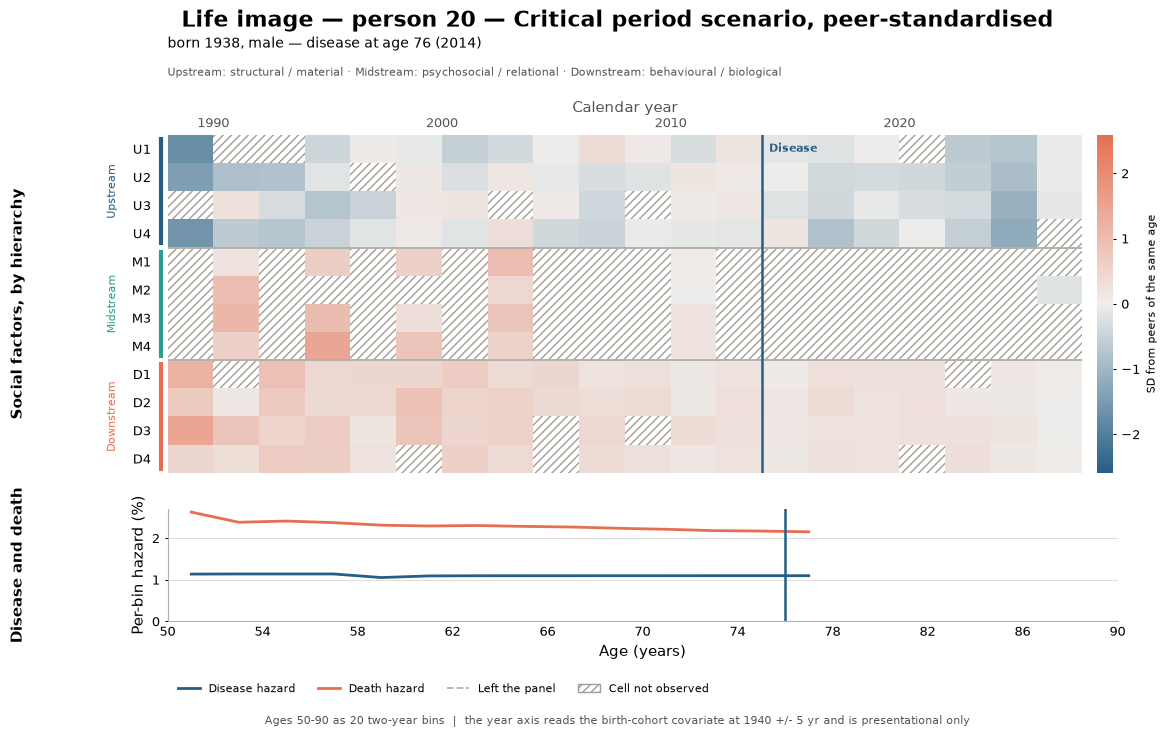

In [4]:
person = people["Disease onset"]

fig = build_life_image(result, cfg, person, STYLE, values, vlim)
written = save_figure(fig, FIGURE_DIR / f"life_image_{SCENARIO}_{SAVE_DATE}", STYLE)
print(P.relative(written))
fig

## Four lives

The four ways a row of this study can end: disease, death, leaving the panel, and
reaching bin 20 with none of the above. Each keeps its own **year** axis — they were
born in different years, so the same ages sit in different decades, which is exactly
why age and year are drawn as two axes rather than one. The **age** axis is shared, at
the bottom.

Under each image is that person's life status per bin, on the same x-axis: the same
separate outcome section as above, compressed to a strip.

output/figures/data_creation/00_data_creation/life_images_gallery_critical_period_20261014.pdf


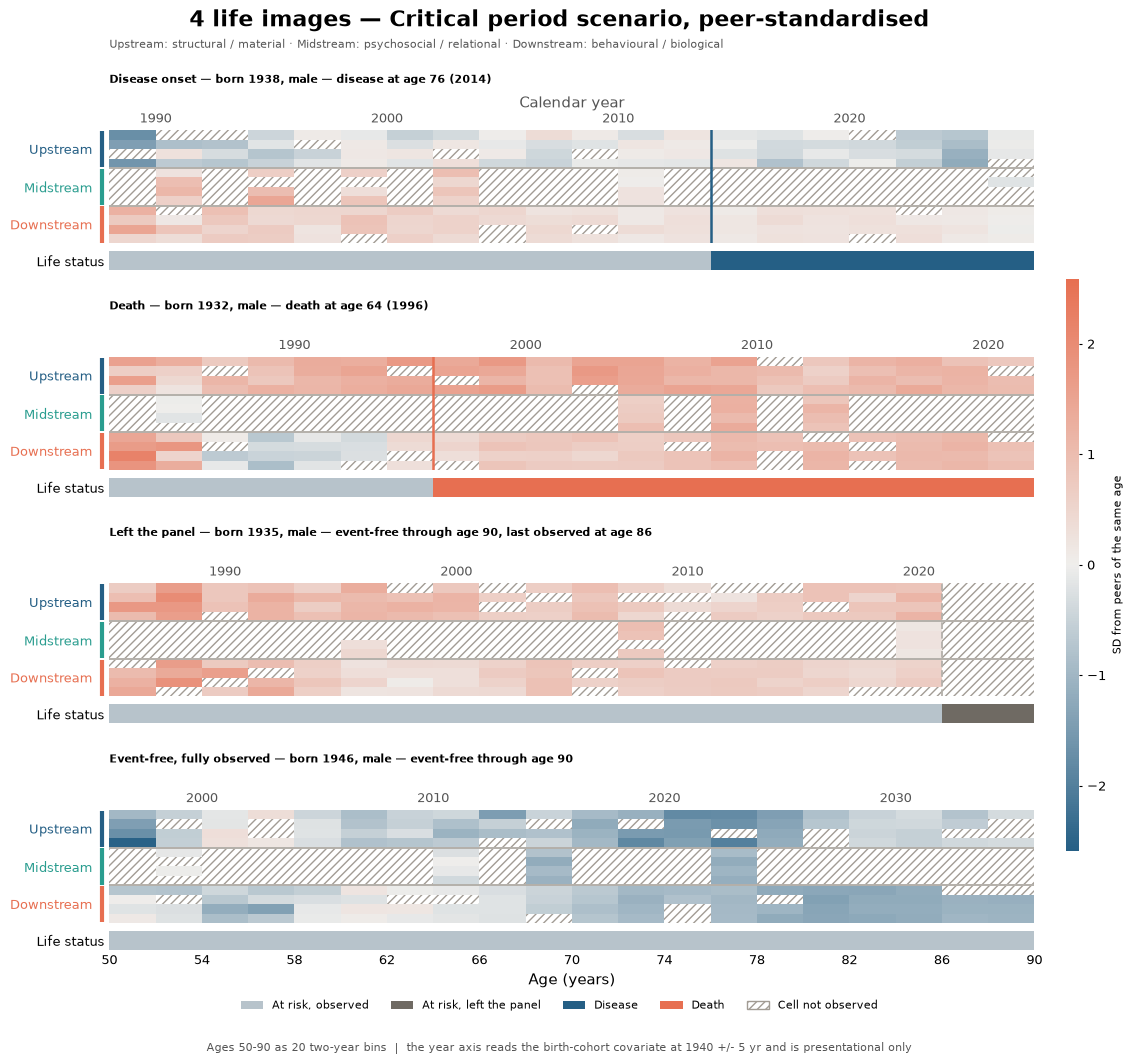

In [5]:
fig = build_life_image_gallery(result, cfg, people, STYLE, values, vlim)
written = save_figure(fig, FIGURE_DIR / f"life_images_gallery_{SCENARIO}_{SAVE_DATE}", STYLE)
print(P.relative(written))
fig

## The same life, in raw units

The same person, the same axes, the colour now the observed value rather than a rank
among peers. Two things change:

- **The level is the picture.** This person's upstream channels sit *below zero in
  absolute terms* for most of the panel, and downstream sits above it. Under `peer` you
  were reading the same thing relative to a moving population mean; here it is the number.
- **The scale has to be this person's own.** The population's 99th percentile of |value|
  is about ±20, while this person's whole life spans about −4 to +3. Drawn on the
  population limit, the entire image would be one flat midtone — the between-person spread
  in the random intercept swamps any one life. So the limit below is taken from this
  person's own cells, which is exactly why raw images cannot be laid side by side and
  compared the way the gallery above can.

That trade is the whole reason `peer` is the default: it is the mode that survives being
put next to another person.

population 99th pct of |value|: +/- 20.04
this person's own 99th pct:      +/- 3.85


output/figures/data_creation/00_data_creation/life_image_critical_period_raw_20261014.pdf


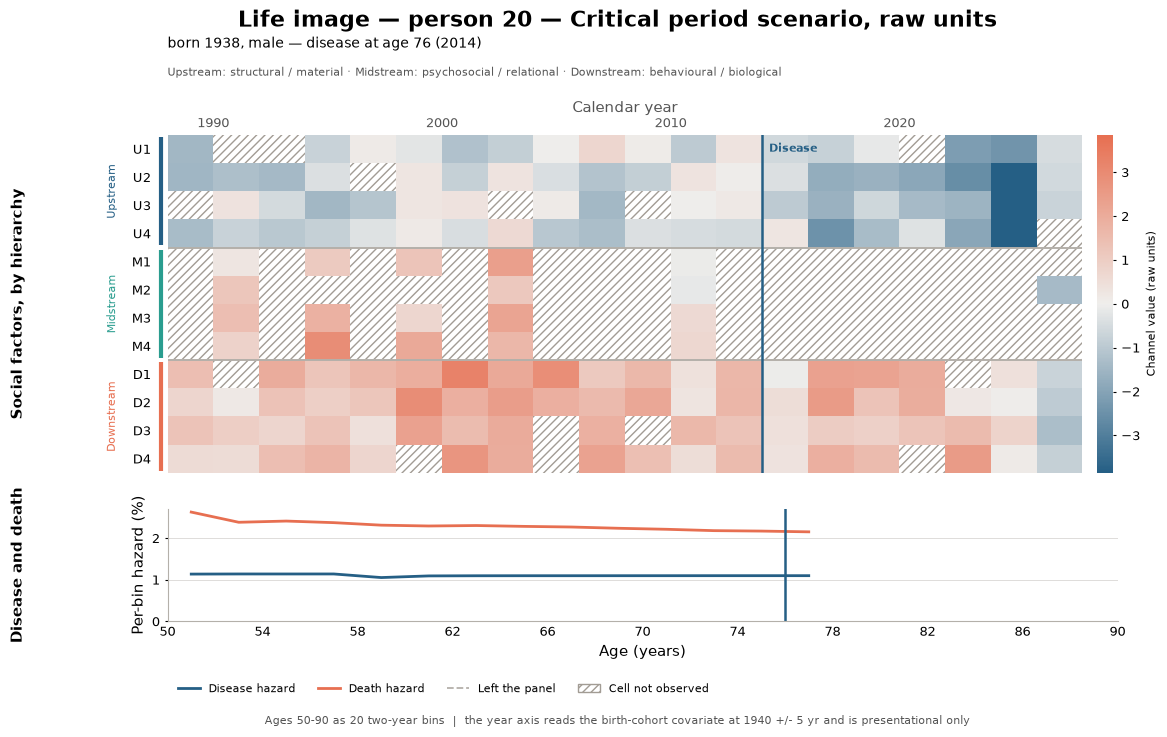

In [6]:
raw = display_values(result, "raw")

population_limit = image_limit(raw)
own_limit = image_limit(raw[[person]])
print(f"population 99th pct of |value|: +/- {population_limit:.2f}")
print(f"this person's own 99th pct:      +/- {own_limit:.2f}")

fig = build_life_image(result, cfg, person, STYLE, raw, own_limit, mode="raw")
written = save_figure(fig, FIGURE_DIR / f"life_image_{SCENARIO}_raw_{SAVE_DATE}", STYLE)
print(P.relative(written))
fig

## Every life, one file each

The per-person export is **the image and nothing else** — no axes, labels, title or
colourbar, and no disease, death or hazard, because a model is shown none of those. One
PNG per person, named by person index, into a scenario subfolder.

| | |
|---|---|
| **columns** | one per calendar year, the **same span for everyone**: the earliest year anyone is observed to the latest. A two-year bin fills two columns. |
| **rows** | the 12 social factors by stream, then **age**, then the **fixed traits** (birth cohort, sex, frailty — the columns of `S`), every row spanning the same ages 50–90 |
| **gray** | no value: a cell not observed, or a year outside this person's ages 50–90 |

Every row is in SD on one colour scale, the population's, so any two files compare
directly. Age is standardised on the clock alone, so a given age is the same colour in
every file. Unlike the figures above, the calendar year here *is* the layout, not a
reading of an axis — see the second note at the end.

`N_EXPORT` people are written, from person 0 upward. Set it to `N` for the whole panel.

In [7]:
N_EXPORT = 10

span = calendar_span(result, cfg.T)
export_dir = FIGURE_DIR / f"life_images_{SCENARIO}"
export_dir.mkdir(parents=True, exist_ok=True)

for person in range(N_EXPORT):
    save_calendar_image(
        calendar_image(result, cfg, values, person, span),
        cfg,
        export_dir / f"person_{person:05d}.{STYLE['export_format']}",
        STYLE,
        vlim,
    )
print(f"calendar span {span[0]}-{span[1] - 1}: {span[1] - span[0]} year columns")
print(f"{N_EXPORT} images -> {P.relative(export_dir)}")

calendar span 1972-2047: 76 year columns
10 images -> output/figures/data_creation/00_data_creation/life_images_critical_period


## The model-input file

The PNGs above are for looking at. What a model is handed is the array itself, written once
per dataset to `data/analysis/data_creation/`, one `.npz` that every model reads:

| keys | what | a model sees it? |
|---|---|---|
| `X`, `M`, `Delta`, `S` | raw channel values (NaN = unobserved), observation mask, bins since last observation, static covariates | **yes** |
| `obs_time`, `obs_type` | the outcome as the panel records it — censored at attrition | trained on it |
| `truth_*` | the DGP's own event times, true hazards, and the weight map `w_true` | **never**; evaluation only |

`X` is stored **raw**, not peer-standardised as in the images: standardising on all 10,000
people would let the test fold's mean and SD into training, so each model standardises on
its own training fold. The file is a cache of a deterministic generation — a model job that
finds it missing writes the identical file from the seed tuple.

In [8]:
model_input = build_model_input(result, cfg)
written = write_model_input(model_input, model_input_path(SCENARIO, N, REPLICATE))
print(P.relative(written))
print({key: value.shape for key, value in [("X", model_input.X), ("S", model_input.S), ("w_true", model_input.truth["truth_w"])]})
print("observed outcomes:", dict(zip(OUTCOME_NAMES, np.bincount(model_input.obs_type, minlength=3).tolist())))

data/analysis/data_creation/model_input_critical_period_n10000_r0.npz
{'X': (10000, 12, 20), 'S': (10000, 3), 'w_true': (12, 20)}
observed outcomes: {'event-free / censored': 7339, 'disease': 1085, 'death': 1576}


## Does standardising on peers of the same age remove the period effect?

**In this simulation there is no period effect to remove.** Calendar time does not exist
in the DGP: `X[i, c, t]` depends on the bin index and on the person, and on nothing else.
The birth-cohort covariate enters the *disease hazard* through `gamma[0] = 0.15` and never
touches a channel. So the mean being subtracted at each bin is purely an **age** mean, and
there is no period signal in the array for it to absorb, hide, or preserve.

**On HRS it would not remove one.** Standardising within `(channel, age-bin)` removes
period only to the extent that age pins down period — and in an accelerated longitudinal
panel it does not. At one age bin you hold many birth cohorts observed in many different
calendar years, so the mean you subtract is a *blend* of the age effect and whatever mix
of periods happens to sit at that age. The residual still carries period: someone measured
in 2010 reads as "low for their age" against a blend that includes 1998 observations, and
that reads back as an individual deviation when it is a macroeconomic one.

Nor is it fixable by choosing a better margin. **Age + cohort = period, exactly**, so
centring on any one of the three cannot separate the other two. Standardising by calendar
year instead would remove period and leave age and cohort confounded in the residual —
the same problem rotated, not solved.

Two smaller things worth being precise about:

- **It does not remove the person's own level.** The cell is centred on the *population*
  at that age, not on that person's own trajectory, so a persistent individual intercept
  survives the transform — which is why one person's upstream row stays blue nearly the
  whole way across in both modes.
- **What it does remove, reliably, is the age trend in the mean and in the variance.**
  That is the job it is doing here, and it is the reason the three streams can share a
  colourbar at all.

If period turns out to matter for the HRS work, the transform to reach for is a two-way
residual — subtract an age-bin margin *and* a calendar-year margin, e.g. by median polish
— accepting that the third margin stays unidentified without an outside restriction. It is
not worth doing on simulated data: this notebook's year axis is fabricated (see below), and
standardising on a fabricated clock would lend it an authority it has not earned.

## Two things to carry forward

**The calendar-year axis is a reading, not a fact.** The DGP has no calendar time. Its
birth-cohort covariate is a standardised normal with no year attached, so the year axis
maps it through `BIRTH_YEAR_MEAN = 1940`, `BIRTH_YEAR_SD = 5` — constants declared in
`src/utils/data_creation_00_data_creation_life_image.py` and used nowhere in the
simulation. In the figures it only labels an axis. In the per-person export it does more:
it sets **which column a cell lands in**, so a year from this clock is now part of what a
model would be shown. On simulated data that is harmless but not neutral — the
critical-period window (ages 58–66) sits in different columns for different birth years,
and a model has to find it through the age row. Treat any column-position effect learned
from these images as a property of the declared clock, not of the DGP.

**The image does not stop at death.** In the gallery, the person who dies at 64 still
has observed cells at 80. That is the DGP as it stands, not a plotting artefact:
`_apply_missingness` truncates a record at `dropout_time` only, and dropout is sampled
only while a person is still at risk, so post-event bins are always "observed". Whether
a life image should be blank after death is a question for the DGP review that
`doc/STATE.md` §3 has open — recorded here because the picture is where it becomes
obvious.